# SentinelOps AI: training the root-cause classifier

**Goal.** Given an incident that the SentinelOps detector has raised from telemetry (request logs and, where they exist, request traces), predict its cause:
`release_regression`, `payment_provider_timeout`, `slow_dependency`, `traffic_surge`, `db_pool_exhaustion`, `cache_unavailable`, `resource_saturation`, `retry_storm`, `unknown` (a real fault with no distinguishing signal), or `no_fault` (a false alarm on healthy traffic). The model must also **abstain** when it is not confident, because a wrong cause leads to a wrong recovery action.

**What this notebook does**
1. Generates labelled incidents with a parametric simulator (random traffic, noise, cold starts, missing logs, partial faults, decoy deployments).
2. Extracts features with the production detector, from telemetry only: no label can leak into the features. Version 2 adds trace features (time waiting for a connection, in queries, in failed cache calls and on-CPU, provider calls per request); without traces they are 0.
3. Trains and tunes three algorithms with stratified 5-fold cross-validation: logistic regression, random forest, gradient boosting.
4. Calibrates probabilities and picks an abstention threshold on a separate validation split.
5. Tests on two held-out sets: **in-distribution** (same simulator settings, unseen seeds) and **shifted** (sparser, noisier, more decoys and missing logs) to measure robustness.
6. Compares against the current rule-based engine on identical inputs, explains the model, analyses errors, and exports it.

**Honest scope.** All data is simulated. A model trained here learns the simulator's patterns; the shifted test set measures robustness to one kind of change, not performance on real incidents. Real labelled incidents are needed before trusting the numbers in production.

In [1]:
import json, sys, time, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, joblib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from training.generator import CLASSES, STANDARD, SHIFTED, generate
from training.features import FEATURES, extract

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 20261027
rng = np.random.default_rng(SEED)
LABELS = CLASSES + ["no_fault"]          # "none" (healthy traffic) becomes no_fault when the detector fires anyway
ACTIONABLE = {"release_regression", "payment_provider_timeout", "slow_dependency", "db_pool_exhaustion",
              "cache_unavailable", "resource_saturation", "retry_storm"}  # causes with a recovery action
print("python", platform.python_version(), "| sklearn", sklearn.__version__, "| features:", len(FEATURES))

python 3.12.10 | sklearn 1.9.0 | features: 25


## 1. Data

Each sample is one simulated stretch of shop traffic: a healthy baseline, then the last ~100 s with (or without) a fault. Seed ranges never overlap between sets. Only incidents the detector actually raises become rows, exactly as in production; detection misses are counted separately.

In [2]:
def build(dist, seeds, per_class, name):
    rows, misses = [], {}
    for label in CLASSES + ["none"]:
        missed = 0
        for s in range(seeds, seeds + per_class):
            sample = generate(label, s, dist)
            feats, rule = extract(sample.events)
            if feats is None:
                missed += 1
                continue
            rows.append({**feats, "label": "no_fault" if label == "none" else label, "rule": rule,
                         **{f"param_{k}": v for k, v in sample.params.items()}})
        misses[label] = missed
    df = pd.DataFrame(rows)
    print(f"{name}: {len(df)} incidents raised from {per_class * (len(CLASSES) + 1)} simulated runs; detector missed:", misses)
    return df

t0 = time.time()
train_df = build(STANDARD, seeds=0,       per_class=1500, name="train (standard)")
testA_df = build(STANDARD, seeds=100_000, per_class=400,  name="test A (standard, unseen seeds)")
testB_df = build(SHIFTED,  seeds=200_000, per_class=400,  name="test B (shifted distribution)")
print(f"generated in {time.time() - t0:.0f}s")
train_df["label"].value_counts().rename("train rows per class").to_frame()

train (standard): 12711 incidents raised from 15000 simulated runs; detector missed: {'release_regression': 1, 'payment_provider_timeout': 114, 'slow_dependency': 99, 'traffic_surge': 540, 'db_pool_exhaustion': 112, 'cache_unavailable': 10, 'resource_saturation': 2, 'retry_storm': 154, 'unknown': 3, 'none': 1254}


test A (standard, unseen seeds): 3405 incidents raised from 4000 simulated runs; detector missed: {'release_regression': 1, 'payment_provider_timeout': 41, 'slow_dependency': 28, 'traffic_surge': 132, 'db_pool_exhaustion': 27, 'cache_unavailable': 2, 'resource_saturation': 0, 'retry_storm': 38, 'unknown': 2, 'none': 324}


test B (shifted distribution): 3074 incidents raised from 4000 simulated runs; detector missed: {'release_regression': 22, 'payment_provider_timeout': 107, 'slow_dependency': 113, 'traffic_surge': 72, 'db_pool_exhaustion': 142, 'cache_unavailable': 59, 'resource_saturation': 25, 'retry_storm': 123, 'unknown': 15, 'none': 248}
generated in 1397s


,train rows per class
label,
release_regression,1499
resource_saturation,1498
unknown,1497
cache_unavailable,1490
slow_dependency,1401
db_pool_exhaustion,1388
payment_provider_timeout,1386
retry_storm,1346
traffic_surge,960


Healthy traffic still produces some detector alarms (noise and cold-start outliers); those become the `no_fault` class, so the model can learn to say "this is not a real incident". Classes are imbalanced, which is why the models below use balanced class weights and macro-F1.

In [3]:
summary = train_df.groupby("label")[["err_recent", "log_p95_ratio", "version_changed", "exception_ratio",
                                      "timeout_match_share", "log_volume_ratio", "fast_fail_ratio"]].mean().round(2)
summary

,err_recent,log_p95_ratio,version_changed,exception_ratio,timeout_match_share,log_volume_ratio,fast_fail_ratio
label,,,,,,,
cache_unavailable,0.02,2.74,0.25,0.00,0.00,-0.42,0.05
db_pool_exhaustion,0.02,2.46,0.25,0.00,0.00,-0.60,0.09
no_fault,0.06,1.16,0.25,0.00,0.00,-0.29,0.27
payment_provider_timeout,0.65,2.97,0.23,0.00,0.73,-0.70,0.03
release_regression,0.67,-0.31,1.00,0.78,0.00,-0.23,0.99
resource_saturation,0.02,2.36,0.26,0.00,0.00,-0.49,0.03
retry_storm,0.17,2.37,0.24,0.00,0.00,-0.52,0.05
slow_dependency,0.02,2.53,0.27,0.00,0.00,-0.60,0.07
traffic_surge,0.09,1.06,0.26,0.00,0.00,1.22,0.16


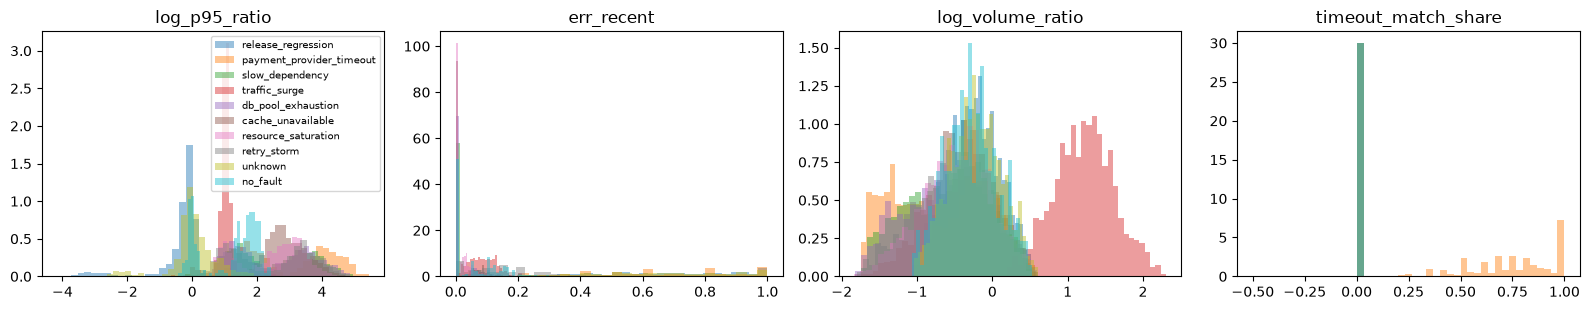

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, feat in zip(axes, ["log_p95_ratio", "err_recent", "log_volume_ratio", "timeout_match_share"]):
    for lab in LABELS:
        vals = train_df.loc[train_df.label == lab, feat]
        ax.hist(vals, bins=30, alpha=0.45, label=lab, density=True)
    ax.set_title(feat)
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

The classes overlap on single features (for example decoy deployments make `version_changed` appear outside `release_regression`), so no single threshold separates them. That is what a learned model should handle better than hand-set rules.

## 2. Train / validation split

The training set is split once: 80% for model selection (cross-validation) and fitting, 20% held back for calibration checks and for choosing the abstention threshold. Test sets A and B are not touched until the end.

In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
X, y = train_df[FEATURES].to_numpy(), train_df["label"].to_numpy()
X_fit, X_val, y_fit, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("fit:", X_fit.shape, "| validation:", X_val.shape)

fit: (10168, 25) | validation: (2543, 25)


## 3. Algorithms and hyper-parameter search

Three model families, each tuned by grid search with stratified 5-fold CV on macro-F1 (every class counts equally, so rare classes are not ignored):

| Model | Why |
| --- | --- |
| Logistic regression (multinomial, standardized inputs) | Simple, interpretable baseline; linear decision boundaries |
| Random forest | Non-linear, robust to feature scale and outliers |
| Histogram gradient boosting | Usually strongest on tabular data; captures interactions |

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

searches = {
    "logistic_regression": GridSearchCV(
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
        {"logisticregression__C": [0.1, 0.3, 1, 3, 10]}, scoring="f1_macro", cv=cv, n_jobs=-1),
    "random_forest": GridSearchCV(
        RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
        {"max_depth": [None, 12], "min_samples_leaf": [1, 3, 8]}, scoring="f1_macro", cv=cv, n_jobs=-1),
    "gradient_boosting": GridSearchCV(
        HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED, early_stopping=False),
        {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31], "l2_regularization": [0.0, 1.0], "max_iter": [300]},
        scoring="f1_macro", cv=cv, n_jobs=-1),
}
cv_table = []
for name, gs in searches.items():
    t0 = time.time(); gs.fit(X_fit, y_fit)
    i = gs.best_index_
    cv_table.append({"model": name, "cv_macro_f1": gs.cv_results_["mean_test_score"][i],
                     "cv_std": gs.cv_results_["std_test_score"][i], "best_params": gs.best_params_,
                     "fit_seconds": round(time.time() - t0, 1)})
cv_df = pd.DataFrame(cv_table).sort_values("cv_macro_f1", ascending=False)
cv_df

,model,cv_macro_f1,cv_std,best_params,fit_seconds
1,random_forest,0.938909,0.008878,"{'max_depth': None, 'min_samples_leaf': 1}",7.3
2,gradient_boosting,0.938471,0.005405,"{'l2_regularization': 1.0, 'learning_rate': 0....",39.1
0,logistic_regression,0.895448,0.008453,{'logisticregression__C': 10},17.0


In [7]:
best_name = cv_df.iloc[0]["model"]
print("selected by cross-validated macro-F1:", best_name, cv_df.iloc[0]["best_params"])

selected by cross-validated macro-F1: random_forest {'max_depth': None, 'min_samples_leaf': 1}


## 4. Calibration

A probability of 0.9 should be right about 90% of the time; otherwise the abstention threshold is meaningless. The selected configuration is refit inside `CalibratedClassifierCV` (5-fold) with both isotonic and sigmoid (Platt) calibration; the one with the lower validation log loss is kept. Isotonic can produce hard 0/1 probabilities that log loss punishes heavily when wrong, so it is not assumed to win.

In [8]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone
from sklearn.metrics import log_loss, accuracy_score, f1_score

base = clone(searches[best_name].best_estimator_)
uncal = clone(base).fit(X_fit, y_fit)
candidates = {m: CalibratedClassifierCV(clone(base), method=m, cv=5).fit(X_fit, y_fit) for m in ("isotonic", "sigmoid")}
classes = list(uncal.classes_)

def brier(proba, y_true):
    onehot = (np.array(y_true)[:, None] == np.array(classes)[None, :]).astype(float)
    return float(np.mean(np.sum((proba - onehot) ** 2, axis=1)))

cal_rows = []
for nm, m in (("uncalibrated", uncal), *candidates.items()):
    p = m.predict_proba(X_val)
    cal_rows.append({"probabilities": nm, "log_loss": log_loss(y_val, p, labels=classes), "brier": brier(p, y_val),
                     "macro_f1": f1_score(y_val, m.predict(X_val), average="macro")})
cal_df = pd.DataFrame(cal_rows).round(4)
CALIBRATION = cal_df[cal_df.probabilities != "uncalibrated"].sort_values("log_loss").iloc[0]["probabilities"]
model = candidates[CALIBRATION]
print("kept calibration:", CALIBRATION); cal_df

kept calibration: sigmoid


,probabilities,log_loss,brier,macro_f1
0,uncalibrated,0.1327,0.0658,0.9338
1,isotonic,0.1569,0.0625,0.9369
2,sigmoid,0.1512,0.0670,0.9334


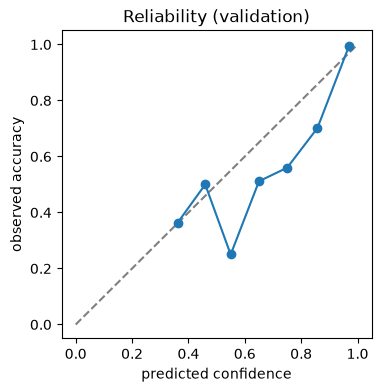

In [9]:
p_val = model.predict_proba(X_val)
conf, correct = p_val.max(axis=1), (np.array(classes)[p_val.argmax(axis=1)] == y_val)
bins = np.linspace(0, 1, 11); idx = np.digitize(conf, bins) - 1
xs, ys = [], []
for b in range(10):
    m = idx == b
    if m.sum() >= 10:
        xs.append(conf[m].mean()); ys.append(correct[m].mean())
plt.figure(figsize=(4, 4)); plt.plot([0, 1], [0, 1], "--", color="grey"); plt.plot(xs, ys, "o-")
plt.xlabel("predicted confidence"); plt.ylabel("observed accuracy"); plt.title("Reliability (validation)"); plt.show()

## 5. Abstention threshold

The model names a cause only when its top probability is at least τ; otherwise it answers `unknown` (no action is recommended). τ is chosen on the validation split as the **smallest** value at which the precision of the non-abstained answers reaches **99%**, which keeps coverage as high as possible under that constraint. The target is strict because a wrong named cause leads to a wrong recovery action.

In [10]:
def decide(proba, tau):
    top = np.array(classes)[proba.argmax(axis=1)]
    return np.where(proba.max(axis=1) >= tau, top, "unknown")

grid = []
for tau in np.round(np.arange(0.30, 0.991, 0.01), 2):
    pred = decide(p_val, tau)
    named = pred != "unknown"
    prec = (pred[named] == y_val[named]).mean() if named.any() else 1.0
    grid.append({"tau": tau, "coverage": named.mean(), "precision_when_named": prec})
grid = pd.DataFrame(grid)
TARGET_PRECISION = 0.99
ok = grid[grid.precision_when_named >= TARGET_PRECISION]
TAU = float(ok.tau.min()) if len(ok) else 0.99
print("chosen tau =", TAU); grid[grid.tau.isin(sorted({0.3, 0.5, 0.7, TAU, 0.9}))]

chosen tau = 0.87


,tau,coverage,precision_when_named
0,0.30,0.881636,0.945584
20,0.50,0.868266,0.952899
40,0.70,0.836020,0.974600
57,0.87,0.801022,0.991654
60,0.90,0.790798,0.994033


## 6. Held-out evaluation and comparison with the rule engine

Both systems see the same detected incidents. Metrics:
- **exact accuracy / macro-F1**: label exactly right.
- **decision accuracy**: right, or correctly declined to name an actionable cause when the truth is `unknown` or `no_fault`.
- **incorrect intervention rate**: named an actionable cause (one that triggers a recovery action) that is wrong. This is the safety metric from the research question.
- **missed actionable**: the truth had a fix, but the system named no actionable cause.

In [11]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

def scores(y_true, pred):
    y_true, pred = np.asarray(y_true), np.asarray(pred)
    quiet = {"unknown", "no_fault"}
    decision_ok = (pred == y_true) | (np.isin(y_true, list(quiet)) & np.isin(pred, list(quiet)))
    named_action = np.isin(pred, list(ACTIONABLE))
    return {"exact_accuracy": (pred == y_true).mean(), "macro_f1": f1_score(y_true, pred, average="macro", labels=LABELS),
            "decision_accuracy": decision_ok.mean(),
            "incorrect_intervention_rate": (named_action & (pred != y_true)).mean(),
            "missed_actionable_rate": (np.isin(y_true, list(ACTIONABLE)) & ~named_action).mean(),
            "coverage_named": (~np.isin(pred, list(quiet))).mean()}

results, preds = [], {}
for set_name, df in (("A: in-distribution", testA_df), ("B: shifted", testB_df)):
    Xs, ys = df[FEATURES].to_numpy(), df["label"].to_numpy()
    learned = decide(model.predict_proba(Xs), TAU)
    preds[set_name] = (ys, learned, df["rule"].to_numpy())
    for system, pred in (("learned model", learned), ("rule engine", df["rule"].to_numpy())):
        results.append({"test set": set_name, "system": system, "n": len(ys), **scores(ys, pred)})
res = pd.DataFrame(results).set_index(["test set", "system"]).round(3)
res

n  exact_accuracy  macro_f1  \
test set           system                                          
A: in-distribution learned model  3405           0.914     0.910   
                   rule engine    3405           0.470     0.391   
B: shifted         learned model  3074           0.712     0.709   
                   rule engine    3074           0.356     0.291   

                                  decision_accuracy  \
test set           system                             
A: in-distribution learned model              0.921   
                   rule engine                0.480   
B: shifted         learned model              0.746   
                   rule engine                0.384   

                                  incorrect_intervention_rate  \
test set           system                                       
A: in-distribution learned model                        0.006   
                   rule engine                          0.213   
B: shifted         learned model                        0.011   
                   rule engine                          0.264   

                                  missed_actionable_rate  coverage_named  
test set           system                                                 
A: in-distribution learned model                   0.072           0.788  
                   rule engine                     0.275           0.597  
B: shifted         learned model                   0.238           0.587  
                   rule engine                     0.287           0.548

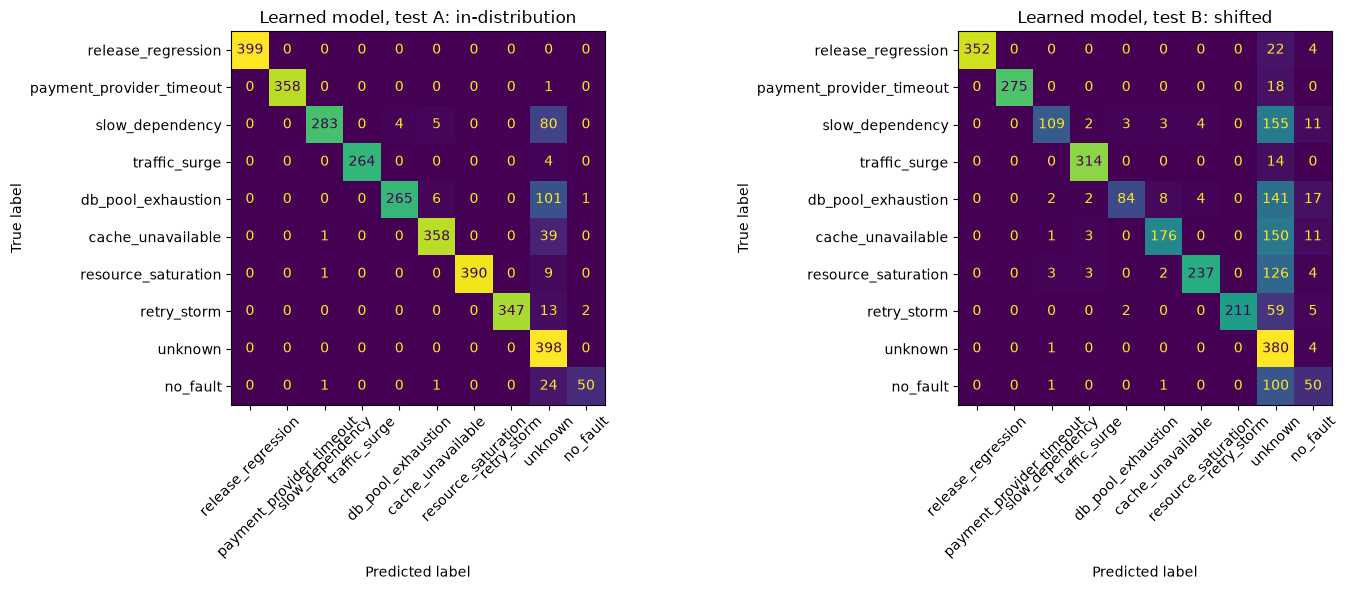

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (set_name, (ys, learned, _)) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(ys, learned, labels=LABELS), display_labels=LABELS).plot(ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(f"Learned model, test {set_name}")
plt.tight_layout(); plt.show()

In [13]:
ys, learned, rule = preds["B: shifted"]
print("Learned model on the shifted test set\n")
print(classification_report(ys, learned, labels=LABELS, zero_division=0, digits=3))

Learned model on the shifted test set

                          precision    recall  f1-score   support

      release_regression      1.000     0.931     0.964       378
payment_provider_timeout      1.000     0.939     0.968       293
         slow_dependency      0.932     0.380     0.540       287
           traffic_surge      0.969     0.957     0.963       328
      db_pool_exhaustion      0.944     0.326     0.484       258
       cache_unavailable      0.926     0.516     0.663       341
     resource_saturation      0.967     0.632     0.765       375
             retry_storm      1.000     0.762     0.865       277
                 unknown      0.326     0.987     0.490       385
                no_fault      0.472     0.329     0.388       152

                accuracy                          0.712      3074
               macro avg      0.854     0.676     0.709      3074
            weighted avg      0.863     0.712     0.730      3074



## 7. What the model relies on

Permutation importance: how much validation macro-F1 drops when one feature is shuffled. Large drops mean the model depends on that feature.

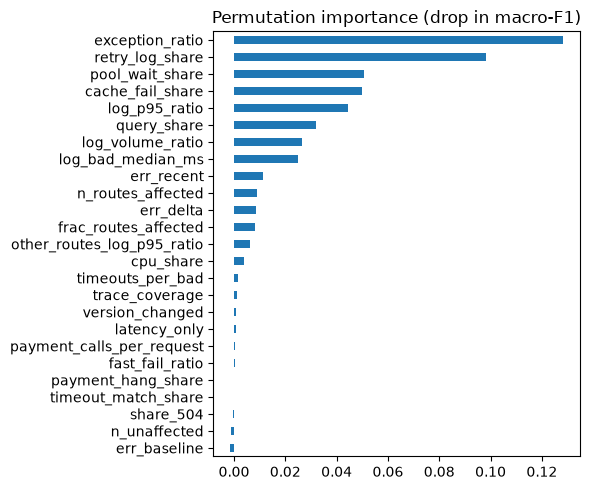

In [14]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(model, X_val, y_val, scoring="f1_macro", n_repeats=8, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.plot.barh(figsize=(6, 5), title="Permutation importance (drop in macro-F1)"); plt.tight_layout(); plt.show()

## 8. Error analysis

Where does the learned model still go wrong on the shifted set, and under which simulated conditions?

In [15]:
dfB = testB_df.assign(pred=preds["B: shifted"][1])
wrong = dfB[dfB.pred != dfB.label]
print(f"{len(wrong)} wrong of {len(dfB)} on the shifted set")
pairs = wrong.groupby(["label", "pred"]).size().sort_values(ascending=False).head(8).rename("count").to_frame()
display(pairs)
cond = dfB.assign(wrong=dfB.pred != dfB.label).groupby(pd.cut(dfB.param_drop, [0, .1, .2, .3]), observed=True)["wrong"].mean()
print("error rate by fraction of missing logs:"); print(cond.round(3))

886 wrong of 3074 on the shifted set


,,count
label,pred,
slow_dependency,unknown,155
cache_unavailable,unknown,150
db_pool_exhaustion,unknown,141
resource_saturation,unknown,126
no_fault,unknown,100
retry_storm,unknown,59
release_regression,unknown,22
payment_provider_timeout,unknown,18


error rate by fraction of missing logs:
param_drop
(0.0, 0.1]    0.259
(0.1, 0.2]    0.287
(0.2, 0.3]    0.306
Name: wrong, dtype: float64


## 9. Export

The calibrated model is saved with its feature list, classes, abstention threshold, metrics and the exact data specification, so a run can be reproduced and audited. A model card summarises it for reviewers.

In [16]:
out = ROOT / "models"; out.mkdir(exist_ok=True)
artifact = {"model": model, "features": FEATURES, "classes": classes, "tau": TAU, "version": "root-cause-v2"}
joblib.dump(artifact, out / "root_cause_v2.joblib")
meta = {
    "version": "root-cause-v2", "algorithm": best_name, "best_params": cv_df.iloc[0]["best_params"],
    "calibration": f"{CALIBRATION}, 5-fold", "calibration_comparison": cal_df.to_dict(orient="records"), "tau": TAU, "target_precision": TARGET_PRECISION, "features": FEATURES, "classes": classes,
    "cv": cv_df.drop(columns="best_params").to_dict(orient="records"),
    "test_results": {f"{a} | {b}": v for (a, b), v in res.to_dict(orient="index").items()},
    "data": {"generator": "training/generator.py", "train_seeds": [0, 1500], "testA_seeds": [100000, 100400],
             "testB_seeds": [200000, 200400], "train_rows": int(len(train_df)), "testA_rows": int(len(testA_df)), "testB_rows": int(len(testB_df))},
    "environment": {"python": platform.python_version(), "sklearn": sklearn.__version__, "numpy": np.__version__},
}
(out / "root_cause_v2.json").write_text(json.dumps(meta, indent=2, default=str))
print("saved", out / "root_cause_v2.joblib", "and", out / "root_cause_v2.json")

saved C:\Projects_Github\SentinelOps-AI\services\sentinel-api\models\root_cause_v2.joblib and C:\Projects_Github\SentinelOps-AI\services\sentinel-api\models\root_cause_v2.json


In [17]:
reloaded = joblib.load(out / "root_cause_v2.joblib")
check = decide(reloaded["model"].predict_proba(testA_df[FEATURES].to_numpy()[:200]), reloaded["tau"])
assert (check == preds["A: in-distribution"][1][:200]).all()
print("reloaded model reproduces the test predictions")

reloaded model reproduces the test predictions


## 10. Compact serving model for the API (shadow mode)

The selected model is about 29 MB (five calibrated copies of a 300-tree forest), too large to ship inside the API image. For **shadow mode** (the API records a prediction next to the rule engine's, without acting on it) a compact logistic regression is exported as a few kilobytes of JSON and served by pure-Python code (`app/analysis/learned.py`), with no pickle loading on the server. It gets its own abstention threshold for 99% precision on validation, and its own held-out results, so the trade-off against the forest is visible.

In [18]:
from app.analysis.learned import ServingModel

lr_C = searches["logistic_regression"].best_params_["logisticregression__C"]
serving = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced", C=lr_C)).fit(X_fit, y_fit)
s_classes = list(serving.classes_)
p_val_s = serving.predict_proba(X_val)

def decide_s(proba, tau):
    top = np.array(s_classes)[proba.argmax(axis=1)]
    return np.where(proba.max(axis=1) >= tau, top, "unknown")

TAU_S = 0.99
for tau in np.round(np.arange(0.30, 0.991, 0.01), 2):
    pred = decide_s(p_val_s, tau); named = pred != "unknown"
    if named.any() and (pred[named] == y_val[named]).mean() >= TARGET_PRECISION:
        TAU_S = float(tau); break
print("serving model: C =", lr_C, "| tau =", TAU_S, "| validation log loss", round(log_loss(y_val, p_val_s, labels=s_classes), 4))

serving_results = []
for set_name, df in (("A: in-distribution", testA_df), ("B: shifted", testB_df)):
    ys = df["label"].to_numpy()
    serving_results.append({"test set": set_name, "system": "serving LR (shadow)", **scores(ys, decide_s(serving.predict_proba(df[FEATURES].to_numpy()), TAU_S))})
    serving_results.append({"test set": set_name, "system": f"selected {best_name}", **scores(ys, preds[set_name][1])})
pd.DataFrame(serving_results).set_index(["test set", "system"]).round(3)

serving model: C = 10 | tau = 0.82 | validation log loss 0.1889


exact_accuracy  macro_f1  \
test set           system                                             
A: in-distribution serving LR (shadow)              0.871     0.858   
                   selected random_forest           0.914     0.910   
B: shifted         serving LR (shadow)              0.694     0.689   
                   selected random_forest           0.712     0.709   

                                           decision_accuracy  \
test set           system                                      
A: in-distribution serving LR (shadow)                 0.882   
                   selected random_forest              0.921   
B: shifted         serving LR (shadow)                 0.719   
                   selected random_forest              0.746   

                                           incorrect_intervention_rate  \
test set           system                                                
A: in-distribution serving LR (shadow)                           0.001   
                   selected random_forest                        0.006   
B: shifted         serving LR (shadow)                           0.005   
                   selected random_forest                        0.011   

                                           missed_actionable_rate  \
test set           system                                           
A: in-distribution serving LR (shadow)                      0.116   
                   selected random_forest                   0.072   
B: shifted         serving LR (shadow)                      0.272   
                   selected random_forest                   0.238   

                                           coverage_named  
test set           system                                  
A: in-distribution serving LR (shadow)              0.744  
                   selected random_forest           0.788  
B: shifted         serving LR (shadow)              0.570  
                   selected random_forest           0.587

In [19]:
scaler, lr = serving.named_steps["standardscaler"], serving.named_steps["logisticregression"]
spec = {"version": "root-cause-serving-v2", "algorithm": "logistic_regression", "C": lr_C, "features": FEATURES,
        "classes": s_classes, "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist(),
        "coef": lr.coef_.tolist(), "intercept": lr.intercept_.tolist(), "tau": TAU_S, "target_precision": TARGET_PRECISION,
        "results": {f"{r['test set']}": {k: float(v) for k, v in r.items() if k not in ("test set", "system")}
                    for r in serving_results if r["system"].startswith("serving")},
        "trained_on": "simulated incidents (training/generator.py), see models/MODEL_CARD.md"}
serve_path = ROOT / "app" / "models" / "root_cause_serving_v2.json"
serve_path.write_text(json.dumps(spec, indent=1))
print("wrote", serve_path, f"({serve_path.stat().st_size / 1024:.1f} KB)")

# Parity: the pure-Python server must reproduce scikit-learn's probabilities exactly.
py_model = ServingModel(spec)
Xa = testA_df[FEATURES]
sk = serving.predict_proba(Xa.to_numpy())
py = np.array([[py_model.predict_proba(dict(zip(FEATURES, row)))[c] for c in s_classes] for row in Xa.to_numpy()])
print("max |sklearn - pure python| probability difference:", float(np.abs(sk - py).max()))
assert np.abs(sk - py).max() < 1e-9

wrote C:\Projects_Github\SentinelOps-AI\services\sentinel-api\app\models\root_cause_serving_v2.json (9.2 KB)


max |sklearn - pure python| probability difference: 1.2212453270876722e-15


## 11. Conclusions and limits

- Read the comparison table in section 6 for the actual numbers of this run; the model card in `models/MODEL_CARD.md` records them.
- The learned model is trained and tested on **simulated** incidents. Its advantage over the rule engine is measured on data from the same simulator family; the shifted set shows how much of it survives one kind of distribution change.
- The rule engine still has things this classifier does not: per-hypothesis evidence with source links and falsification tests. The intended use is to **combine** them (the model ranks causes; the ledger and diagnostics justify and challenge the ranking), not to replace the evidence trail with a bare prediction.
- The compact serving model runs in the API in **shadow mode** only: it records its answer next to the rule engine's for every incident and never influences a recovery action. Labelled real incidents exported from the API (`GET /api/v1/training/labelled`) are the next evaluation set.